<a href="https://colab.research.google.com/github/catarina1532/project-template/blob/main/EDA_EucaNutri_RAIZ_Workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Bloco 1 — Carregar e preparar os dados**

O que queremos investigar: conseguir ler as diferentes tabelas e confirmar que estamos a utilizar a versão atualizada dos dados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io
import sqlite3

from google.colab import files
from IPython.display import display

# Upload do ficheiro ZIP
uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))
zip_file = zipfile.ZipFile(io.BytesIO(uploaded[zip_name]))

# Carregar Excel
excel_bytes = zip_file.read("eucanutri/eucanutri_visualizacao.xlsx")
excel = pd.ExcelFile(io.BytesIO(excel_bytes))

# Carregar tabelas
folhas = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="folha_tabela")
solo = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="solo_tabela")
diagnose = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="diagnose_visual")
observacoes = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="observacoes")
referencias = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="referencia_classes")

# Carregar dados climáticos
clima_bytes = zip_file.read("eucanutri/clima_indicadores.csv")
clima = pd.read_csv(io.BytesIO(clima_bytes), sep=";")

print("DADOS CARREGADOS COM SUCESSO")
print("-" * 50)

for nome, tabela in {
    "Folhas": folhas,
    "Solo": solo,
    "Diagnóstico visual": diagnose,
    "Observações": observacoes,
    "Referências": referencias,
    "Clima": clima
}.items():
    print(f"{nome}: {tabela.shape[0]} registos | {tabela.shape[1]} variáveis")

Saving eucanutri (3).zip to eucanutri (3).zip
DADOS CARREGADOS COM SUCESSO
--------------------------------------------------
Folhas: 190 registos | 25 variáveis
Solo: 144 registos | 28 variáveis
Diagnóstico visual: 154 registos | 11 variáveis
Observações: 144 registos | 10 variáveis
Referências: 145 registos | 8 variáveis
Clima: 144 registos | 14 variáveis


O carregamento foi realizado com sucesso, permitindo identificar cinco tabelas principais de informação RAIZ, uma tabela de referências nutricionais e uma fonte adicional de dados climáticos.

A base de dados apresenta diferentes níveis de observação:
- 144 registos de visitas/observações;
- 190 registos de análises foliares;
- 144 registos de análises de solo;
- 154 registos de diagnóstico visual;
- 144 registos climáticos associados às visitas.

A diferença no número de registos demonstra que nem todas as fontes têm uma correspondência de um para um. Esta característica deve ser considerada durante a integração e a preparação dos dados para modelação.

**Bloco 2 — Auditoria da qualidade dos dados**

O que queremos investigar:
- Quantos registos existem em cada tabela?
- Existem duplicados?
- Existem valores omissos?
- Os identificadores estão corretamente organizados?
- Existem problemas que possam prejudicar a integração?

In [2]:
# 1. Resumo geral — auditoria de todas as tabelas

tabelas = {
    "Folhas": folhas,
    "Solo": solo,
    "Diagnóstico visual": diagnose,
    "Observações": observacoes,
    "Referências": referencias,
    "Clima": clima
}

resumo = []

for nome, df in tabelas.items():

    # Identificar a coluna de identificação, quando existe
    if "id" in df.columns:
        coluna_id = "id"
    elif "localizacao_id" in df.columns:
        coluna_id = "localizacao_id"
    else:
        coluna_id = None

    # Contar IDs únicos apenas quando existe uma coluna adequada
    ids_unicos = (
        df[coluna_id].nunique()
        if coluna_id is not None
        else np.nan
    )

    resumo.append({
        "Tabela": nome,
        "Registos": len(df),
        "Variáveis": len(df.columns),
        "Linhas duplicadas": df.duplicated().sum(),
        "Valores omissos": df.isna().sum().sum(),
        "Coluna ID": coluna_id if coluna_id else "Não aplicável",
        "IDs únicos": ids_unicos
    })

resumo_qualidade = pd.DataFrame(resumo)

display(resumo_qualidade)

,Tabela,Registos,Variáveis,Linhas duplicadas,Valores omissos,Coluna ID,IDs únicos
0,Folhas,190,25,0,511,id,143.0
1,Solo,144,28,0,916,id,143.0
2,Diagnóstico visual,154,11,0,235,id,144.0
3,Observações,144,10,0,20,id,144.0
4,Referências,145,8,0,60,Não aplicável,NaN
5,Clima,144,14,0,21,localizacao_id,144.0


In [3]:
# 2. Valores omissos por variável — todas as tabelas

for nome, df in tabelas.items():

    print("\n", nome.upper())

    missing = pd.DataFrame({
        "Valores omissos": df.isna().sum(),
        "Percentagem (%)": (df.isna().mean() * 100).round(1)
    })

    display(
        missing[missing["Valores omissos"] > 0]
        .sort_values("Percentagem (%)", ascending=False)
    )


 FOLHAS


,Valores omissos,Percentagem (%)
C,166,87.4
parcela,162,85.3
zona_homogenea,119,62.6
S,64,33.7



 SOLO


,Valores omissos,Percentagem (%)
zona_homogenea,124,86.1
textura,124,86.1
terra_fina_pct,123,85.4
N,102,70.8
ce_dsm,102,70.8
classe_B,80,55.6
B,60,41.7
Mn,40,27.8
Cu,40,27.8
Fe,40,27.8



 DIAGNÓSTICO VISUAL


,Valores omissos,Percentagem (%)
material_genetico,126,81.8
obs,43,27.9
tipo_desordem,29,18.8
abrangencia,23,14.9
desordem_nutricional,7,4.5
desordem_nao_nutricional,6,3.9
vitalidade_normal,1,0.6


... (2 outputs left out)


 REFERÊNCIAS


,Valores omissos,Percentagem (%)
minimo_incl,30,20.7
maximo_excl,30,20.7



 CLIMA


,Valores omissos,Percentagem (%)
temp_media_anual,3,2.1
temp_max_absoluta,3,2.1
temp_min_absoluta,3,2.1
humidade_solo_l1,3,2.1
humidade_solo_l2,3,2.1
amplitude_termica_anual,3,2.1
gradiente_humidade_solo,3,2.1


In [4]:
# 4. Comparar os IDs entre fontes de dados

ids_observacoes = set(observacoes["id"].dropna())
ids_folhas = set(folhas["id"].dropna())
ids_solo = set(solo["id"].dropna())
ids_diagnostico = set(diagnose["id"].dropna())

print("IDs sem amostras foliares:",
      sorted(ids_observacoes - ids_folhas))

print("IDs sem análises de solo:",
      sorted(ids_observacoes - ids_solo))

print("IDs sem diagnóstico visual:",
      sorted(ids_observacoes - ids_diagnostico))

# Visitas com as três fontes disponíveis
ids_completos = (
    ids_observacoes
    & ids_folhas
    & ids_solo
    & ids_diagnostico
)

print("\nVisitas com folhas, solo e diagnóstico visual:",
      len(ids_completos))

print("Visitas sem pelo menos uma destas fontes:",
      len(ids_observacoes - ids_completos))

IDs sem amostras foliares: [32]
IDs sem análises de solo: [32]
IDs sem diagnóstico visual: []

Visitas com folhas, solo e diagnóstico visual: 143
Visitas sem pelo menos uma destas fontes: 1


Interpretação que vamos procurar:
- Os registos repetidos por ID não representam necessariamente erros.
- As 190 amostras foliares não correspondem a 190 visitas independentes.
- As amostras de solo também devem ser identificadas por id + amostra.
- Os valores omissos devem ser interpretados de acordo com a disponibilidade histórica de cada parâmetro.

Uma variável com muitos valores omissos poderá ser menos adequada para a primeira versão do modelo, mas não deve ser automaticamente eliminada.

A auditoria identificou ausência de duplicados completos e ausência de duplicados nas principais chaves de identificação testadas, indicando uma boa consistência estrutural inicial.

Contudo, foram identificados valores omissos em várias variáveis, com maior incidência em alguns parâmetros de solo e em variáveis complementares das análises foliares.

Destacam-se:
- A ausência de carbono em 87,4% das amostras foliares.
- A ausência de zona homogénea e textura em 86,1% dos registos de solo.
- A ausência de azoto no solo em 70,8%.
- A ausência de material genético em 81,8% das fichas de diagnóstico visual.

As variáveis com elevada percentagem de valores omissos exigem uma avaliação antes de serem utilizadas na modelação.

Apesar destas limitações, os principais nutrientes foliares N, P, K e B apresentam dados completos nas 190 amostras, o que permite avançar com a sua análise exploratória.

**Bloco 3 — Verificar a distribuição temporal e regional**

O que queremos investigar: perceber se os dados estão distribuídos de forma equilibrada entre anos e regiões e se existem diferenças na composição da amostra.

Esta informação é importante porque as condições ambientais, a idade dos povoamentos e a região podem influenciar o estado nutricional.

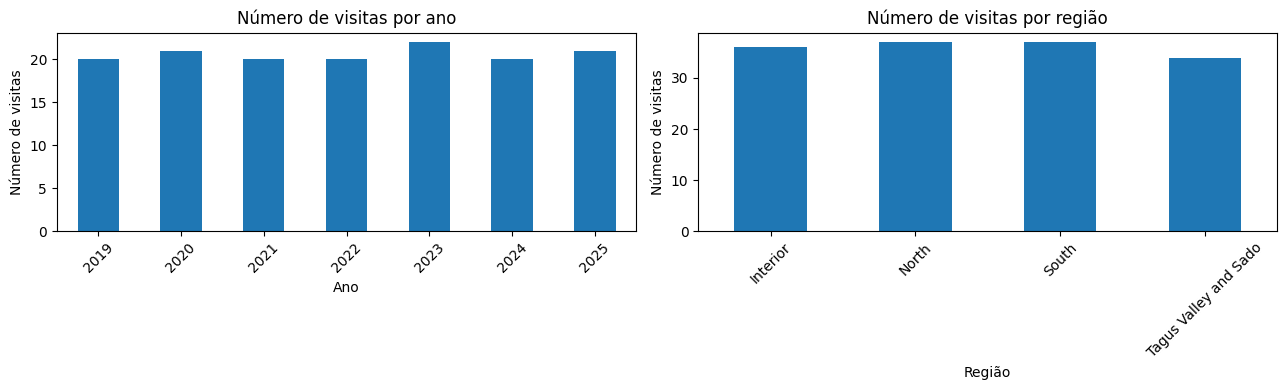

,idade_anos,area_ha,acm
count,144.00,144.00,144.00
mean,1.90,24.21,10.67
std,0.38,25.47,3.73
min,1.20,1.20,2.98
25%,1.60,6.69,8.09
50%,2.00,12.80,10.23
75%,2.01,32.76,12.32
max,3.10,151.20,25.88


,count
regime,
1st rotation,76
Coppice,68


regiao,Interior,North,South,Tagus Valley and Sado
ano,,,,
2019,6,4,6,4
2020,5,5,6,5
2021,5,5,5,5
2022,5,5,5,5
2023,5,7,5,5
2024,5,5,5,5
2025,5,6,5,5


In [5]:
# Número de visitas por ano
visitas_ano = observacoes.groupby("ano")["id"].nunique()

# Número de visitas por região
visitas_regiao = observacoes.groupby("regiao")["id"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

visitas_ano.plot(kind="bar", ax=axes[0])
axes[0].set_title("Número de visitas por ano")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Número de visitas")
axes[0].tick_params(axis="x", rotation=45)

visitas_regiao.plot(kind="bar", ax=axes[1])
axes[1].set_title("Número de visitas por região")
axes[1].set_xlabel("Região")
axes[1].set_ylabel("Número de visitas")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Estatísticas das variáveis de caracterização
display(
    observacoes[["idade_anos", "area_ha", "acm"]]
    .describe()
    .round(2)
)

# Distribuição por regime
display(observacoes["regime"].value_counts())

# Distribuição por região e ano
display(pd.crosstab(observacoes["ano"], observacoes["regiao"]))

O que vamos interpretar:
1. Se existe uma distribuição relativamente equilibrada de visitas entre 2019 e 2025.
2. Se alguma região está particularmente representada ou sub-representada.
3. Qual é a amplitude de idades dos povoamentos.
4. Se existem diferentes regimes de exploração florestal.
5. Se a distribuição temporal e regional poderá introduzir enviesamentos na modelação.

A distribuição temporal apresenta uma cobertura relativamente equilibrada entre 2019 e 2025, com 20 a 22 visitas por ano.

A distribuição regional também é equilibrada, variando entre 34 e 37 visitas por região. Esta distribuição é favorável à realização de análises comparativas regionais, embora não garanta representatividade de todos os povoamentos existentes em cada região.

Relativamente às características dos povoamentos, observa-se uma idade média de 1,90 anos e uma distribuição relativamente concentrada em torno dos dois anos.

A área apresenta uma distribuição assimétrica: a média é 24,21 ha, enquanto a mediana é 12,80 ha, sugerindo a existência de alguns povoamentos de maior dimensão.

Os dois regimes de exploração estão representados de forma relativamente equilibrada, com 76 registos de primeira rotação e 68 de talhadia.

Conclusão para a modelação: ano, região, idade e regime são variáveis de contextualização relevantes. A área também poderá ser considerada, embora a sua distribuição assimétrica deva ser avaliada.

Um detalhe: os gráficos de visitas por ano e região são relevantes, mas a tabela cruzada ano × região é a evidência mais útil para mostrar que não existe uma concentração temporal muito acentuada numa única região.

**Bloco 4 — Análise do estado nutricional das folhas**

O que queremos investigar: conhecer a distribuição dos quatro nutrientes prioritários do problema: azoto (N), fósforo (P), potássio (K) e boro (B).

Estes quatro nutrientes são fundamentais para o diagnóstico visual.

ESTATÍSTICAS DAS CONCENTRAÇÕES FOLIARES


,count,mean,std,min,25%,50%,75%,max
N,190.0,1.520,0.426,0.64,1.30,1.53,1.800,2.60
P,190.0,0.114,0.071,0.06,0.07,0.10,0.130,0.56
K,190.0,0.628,0.172,0.15,0.51,0.60,0.700,1.24
B,190.0,24.537,13.468,4.00,18.00,21.85,28.175,122.40



 CLASSE_N


,count
classe_N,
Média,67
Baixa,58
Muito baixa,38
Alta,27



 CLASSE_P


,count
classe_P,
Baixa,90
Média,64
Alta,28
Muito alta,8



 CLASSE_K


,count
classe_K,
Média,99
Alta,55
Baixa,31
Muito baixa,5



 CLASSE_B


,count
classe_B,
Média,101
Baixa,67
Alta,16
Muito baixa,4
Muito alta,2


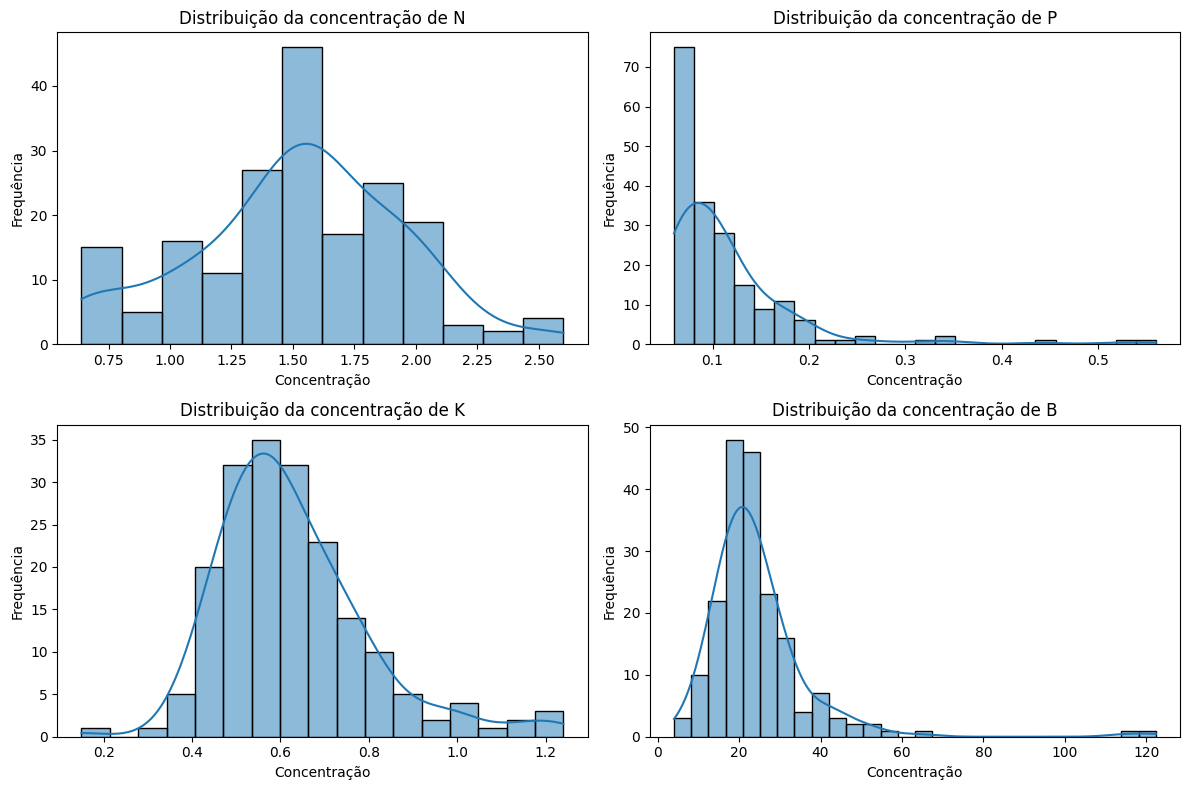

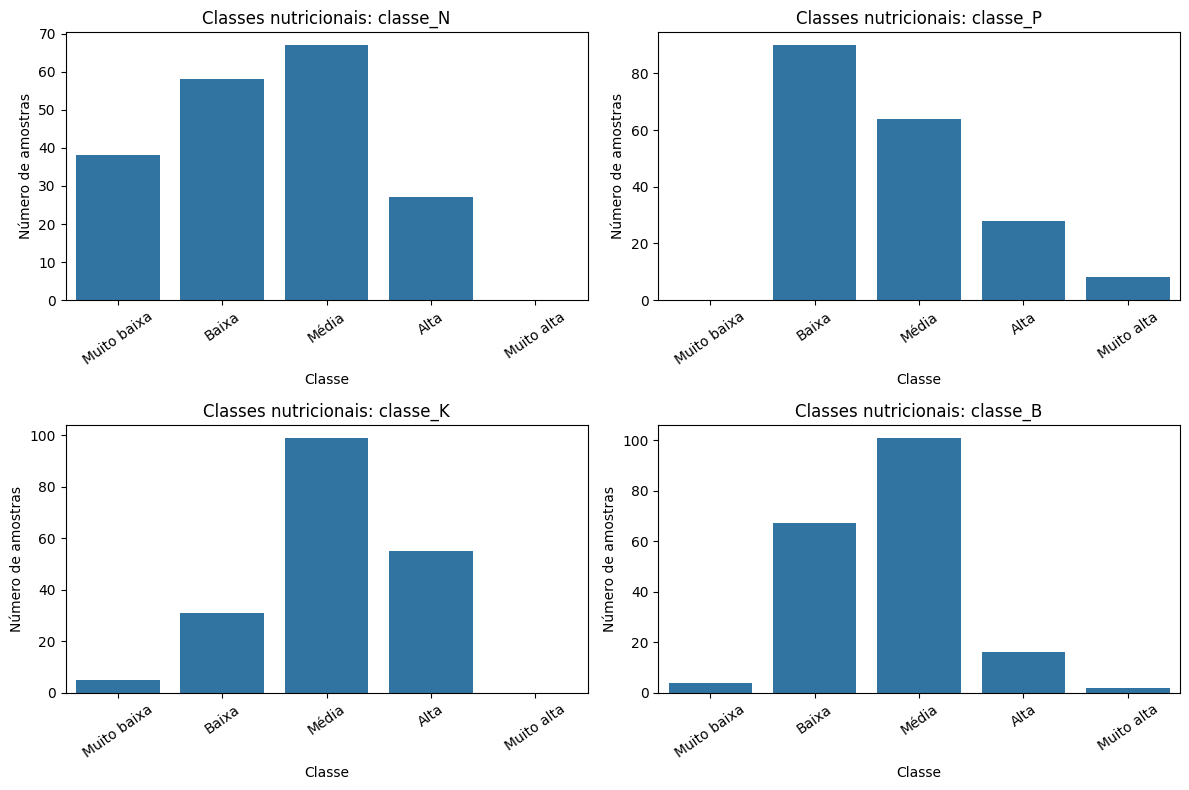

In [6]:
nutrientes = ["N", "P", "K", "B"]

# Estatísticas descritivas
print("ESTATÍSTICAS DAS CONCENTRAÇÕES FOLIARES")

display(
    folhas[nutrientes]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .T
    .round(3)
)

# Distribuição das classes nutricionais
classes = ["classe_N", "classe_P", "classe_K", "classe_B"]

for coluna in classes:
    print("\n", coluna.upper())
    display(folhas[coluna].value_counts(dropna=False))

# Gráficos das concentrações
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, nutriente in zip(axes.flat, nutrientes):
    sns.histplot(
        folhas[nutriente].dropna(),
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribuição da concentração de {nutriente}")
    ax.set_xlabel("Concentração")
    ax.set_ylabel("Frequência")

plt.tight_layout()
plt.show()

# Gráficos das classes nutricionais
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, coluna in zip(axes.flat, classes):
    ordem = ["Muito baixa", "Baixa", "Média", "Alta", "Muito alta"]

    sns.countplot(
        data=folhas,
        x=coluna,
        order=ordem,
        ax=ax
    )

    ax.set_title(f"Classes nutricionais: {coluna}")
    ax.set_xlabel("Classe")
    ax.set_ylabel("Número de amostras")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Resultados preliminares que já podemos antecipar:

A análise inicial dos dados revelou:
| Nutriente | Média | Mínimo | Máximo |
| :--- | :---: | :---: | :---: |
| N | 1,52 | 0,64 | 2,60 |
| P | 0,11 | 0,06 | 0,56 |
| K | 0,63 | 0,15 | 1,24 |
| B | 24,54 | 4,00 | 122,40 |

Concentrações em % de matéria seca para N, P e K; mg/kg para B.

Já se observa que:
- N: 96 das 190 amostras estão nas classes baixa ou muito baixa.
- P: 90 das 190 amostras estão na classe baixa.
- K: 99 das 190 amostras estão na classe média.
- B: 101 das 190 amostras estão na classe média.

Estes resultados são interessantes porque permitem identificar nutrientes que merecem particular atenção na fase de modelação.

Atenção: são contagens de amostras, não de povoamentos independentes. Também não devemos concluir que uma classe baixa representa automaticamente um diagnóstico visual confirmado.

A análise das 190 amostras foliares revela padrões distintos entre os quatro nutrientes prioritários.

Azoto (N): 96 amostras (50,5%) encontram-se nas classes baixa ou muito baixa. É o nutriente que apresenta uma proporção mais elevada de amostras nestas duas classes.

Fósforo (P): 90 amostras (47,4%) estão na classe baixa. A distribuição apresenta uma concentração significativa de observações nesta categoria.

Potássio (K): predomina a classe média, com 99 amostras (52,1%), seguida da classe alta, com 55 amostras (28,9%).

Boro (B): também predomina a classe média, com 101 amostras (53,2%), enquanto 67 amostras (35,3%) se encontram na classe baixa.

Os resultados mostram que N e P merecem particular atenção na análise do estado nutricional, uma vez que apresentam uma proporção relevante de amostras nas classes inferiores.

As distribuições de K e B concentram-se sobretudo nas classes média e baixa.

Estes resultados justificam a utilização das concentrações foliares e das classes nutricionais como variáveis centrais na análise do problema.

Uma precisão importante: no P, as 90 amostras estão na classe baixa, mas nenhuma está na classe muito baixa. Não se deve somar estas categorias como acontece para N.

**Bloco 5 — Relação entre solo e nutrição foliar**

O que queremos investigar: perceber se as características químicas do solo apresentam associações com as concentrações dos nutrientes nas folhas.

Esta análise é relevante porque o problema pretende combinar a informação do solo com a informação da planta.

Vamos começar por selecionar variáveis disponíveis no solo:
- pH;
- matéria orgânica;
- fósforo;
- potássio;
- cálcio;
- magnésio;
- boro;
- saturação em bases.

Como existem várias amostras foliares e, nalguns casos, várias amostras de solo por visita, vamos calcular médias por visita para esta primeira exploração.

Dimensão da tabela integrada: (143, 14)


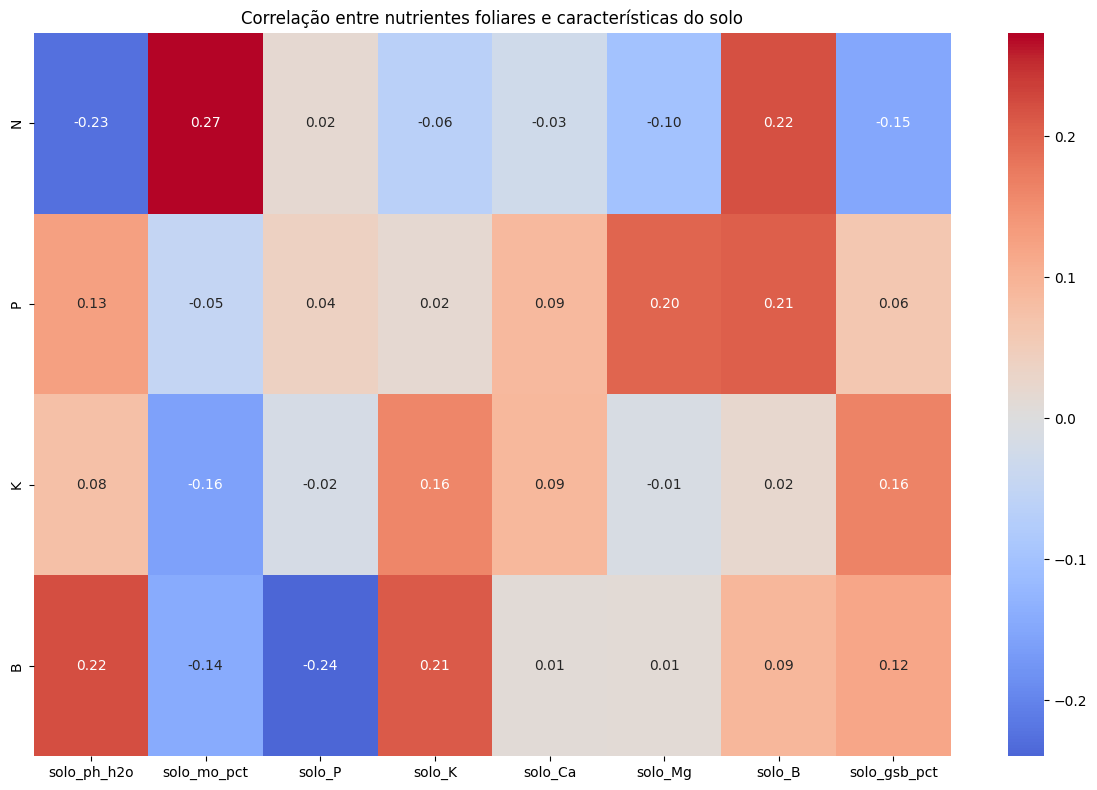

,solo_ph_h2o,solo_mo_pct,solo_P,solo_K,solo_Ca,solo_Mg,solo_B,solo_gsb_pct
N,-0.23,0.27,0.02,-0.06,-0.03,-0.10,0.22,-0.15
P,0.13,-0.05,0.04,0.02,0.09,0.20,0.21,0.06
K,0.08,-0.16,-0.02,0.16,0.09,-0.01,0.02,0.16
B,0.22,-0.14,-0.24,0.21,0.01,0.01,0.09,0.12


In [7]:
# 1. Garantir que os nutrientes foliares são numéricos antes do cálculo
for c in ["N", "P", "K", "B"]:
    folhas[c] = pd.to_numeric(folhas[c], errors='coerce')

folhas_visita = (
    folhas.groupby(["id", "ano"])[["N", "P", "K", "B"]]
    .mean()
    .reset_index()
)

# 2. Garantir que as variáveis do solo são numéricas antes do cálculo
variaveis_solo = [
    "ph_h2o", "mo_pct", "P", "K",
    "Ca", "Mg", "B", "gsb_pct"
]

for c in variaveis_solo:
    solo[c] = pd.to_numeric(solo[c], errors='coerce')

solo_visita = (
    solo.groupby(["id", "ano"])[variaveis_solo]
    .mean()
    .reset_index()
)

# Identificar as variáveis de solo
solo_visita = solo_visita.rename(
    columns={c: f"solo_{c}" for c in variaveis_solo}
)

# Integrar as duas fontes
folha_solo = folhas_visita.merge(
    solo_visita,
    on=["id", "ano"],
    how="inner"
)

print("Dimensão da tabela integrada:", folha_solo.shape)

# Correlações
corr = folha_solo.drop(columns=["id", "ano"]).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr.loc[["N", "P", "K", "B"],
             [f"solo_{v}" for v in variaveis_solo]],
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlação entre nutrientes foliares e características do solo")
plt.tight_layout()
plt.show()

display(
    corr.loc[["N", "P", "K", "B"],
             [f"solo_{v}" for v in variaveis_solo]]
    .round(2)
)

In [8]:
# Análise complementar: azoto foliar vs azoto no solo

solo["N"] = pd.to_numeric(solo["N"], errors="coerce")

# Média de N do solo por visita
solo_N_visita = (
    solo.groupby(["id", "ano"])["N"]
    .mean()
    .reset_index()
    .rename(columns={"N": "N_solo"})
)

# Integrar N foliar e N do solo
folha_solo_N = folhas_visita.merge(
    solo_N_visita,
    on=["id", "ano"],
    how="inner",
    validate="one_to_one"
)

# Pares completos
pares_N = folha_solo_N.dropna(
    subset=["N", "N_solo"]
)

print("Visitas integradas:", len(folha_solo_N))
print("Pares completos N foliar / N solo:", len(pares_N))
print(
    "Visitas sem N do solo disponível:",
    folha_solo_N["N_solo"].isna().sum()
)

# Correlação de Pearson
if len(pares_N) >= 2:
    correlacao_N = pares_N["N"].corr(pares_N["N_solo"])
    print(
        "Correlação de Pearson N foliar / N solo:",
        round(correlacao_N, 3)
    )
else:
    print("Número insuficiente de pares completos.")

# Estatísticas dos pares completos
display(
    pares_N[["N", "N_solo"]]
    .describe()
    .round(3)
)

Visitas integradas: 143
Pares completos N foliar / N solo: 41
Visitas sem N do solo disponível: 102
Correlação de Pearson N foliar / N solo: 0.519


,N,N_solo
count,41.000,41.000
mean,1.713,0.165
std,0.388,0.105
min,1.000,0.050
25%,1.450,0.050
50%,1.600,0.140
75%,2.000,0.250
max,2.600,0.400


O que vamos procurar:

- Se o fósforo no solo apresenta associação com o fósforo foliar.
- Se o potássio no solo apresenta associação com o potássio foliar.
- Se o pH e a matéria orgânica apresentam relações com a nutrição.
- Se existem relações entre o boro no solo e o boro nas folhas.

Não esperamos necessariamente correlações fortes. A absorção de nutrientes depende de vários fatores, incluindo idade, características do solo, disponibilidade de água e condições ambientais.

Nota metodológica: esta análise é exploratória. A média por visita pode esconder diferenças entre clones e amostras. Uma análise posterior deverá preservar essa informação sempre que possível.

A integração das análises foliares e do solo permitiu obter 143 registos correspondentes, possibilitando explorar as relações entre as concentrações de nutrientes na planta e as características físico-químicas do solo.

As correlações observadas são, na sua generalidade, fracas.

Destaca-se uma correlação positiva entre azoto foliar e matéria orgânica do solo (r = 0,27), assim como uma correlação negativa entre boro foliar e fósforo no solo (r = -0,24).

As correlações entre o mesmo nutriente na folha e no solo são também reduzidas: 0,04 para P, 0,16 para K e 0,09 para B.

Estes resultados não demonstram relações lineares fortes entre a concentração de um nutriente no solo e a sua concentração nas folhas.

No entanto, não excluem a relevância das características do solo para explicar o estado nutricional, uma vez que a absorção dos nutrientes depende de diferentes propriedades físico-químicas e de condições ambientais.

Implicação para a modelação: manter as variáveis do solo como candidatas a variáveis explicativas, mas avaliar a sua contribuição individual e conjunta numa fase posterior.
Uma correção necessária no código
Na lista de variáveis do solo não incluíste N, porque tem muitos valores omissos. Isso significa que não estás a analisar a relação entre azoto foliar e azoto no solo.

Não precisas de alterar a análise principal para amanhã. Basta acrescentar uma análise separada de N do solo, verificando primeiro quantos pares completos existem. É possível que a cobertura seja demasiado reduzida.

Decisão: manter este bloco, mas não dedicar demasiado tempo à matriz de correlação no slide. A principal mensagem é que o cruzamento foi possível, embora as relações lineares observadas sejam fracas.

**Bloco 6 — Relação entre diagnóstico visual e nutrição**

O que queremos investigar: perceber se as observações visuais registadas no campo são coerentes com a informação das análises foliares.

O documento do problema destaca que:
- A deficiência de N pode provocar amarelecimento progressivo.
- A deficiência de P pode provocar manchas arroxeadas.
- A deficiência de K pode provocar alterações nas margens das folhas.
- A deficiência de B pode provocar deformações nas folhas jovens e nos ápices.

Mas também alerta que pragas, doenças, geada, seca e encharcamento podem produzir sintomas semelhantes.

In [9]:
# Distribuição das observações de diagnóstico
for coluna in [
    "vitalidade_normal",
    "abrangencia",
    "desordem_nao_nutricional",
    "desordem_nutricional"
]:
    print("\n", coluna)
    display(diagnose[coluna].value_counts(dropna=False))

# Distribuição das desordens não nutricionais
print("\nTIPOS DE DESORDENS NÃO NUTRICIONAIS")
display(diagnose["tipo_desordem"].value_counts(dropna=False))

# Relação entre vitalidade e presença de sintomas nutricionais
tabela_diagnostico = pd.crosstab(
    diagnose["vitalidade_normal"],
    diagnose["desordem_nutricional"],
    margins=True
)

display(tabela_diagnostico)

# Relação entre desordens nutricionais e não nutricionais
display(
    pd.crosstab(
        diagnose["desordem_nutricional"],
        diagnose["desordem_nao_nutricional"],
        margins=True
    )
)


 vitalidade_normal


,count
vitalidade_normal,
N,113
S,40
NaN,1



 abrangencia


,count
abrangencia,
G,92
P,39
NaN,23



 desordem_nao_nutricional


,count
desordem_nao_nutricional,
CS,124
SS,24
NaN,6


... (2 outputs left out)


TIPOS DE DESORDENS NÃO NUTRICIONAIS


,count
tipo_desordem,
Pragas/doenças,64
NaN,29
Pragas/doenças; Encharcamento,7
Pragas/doenças e geada,5
Vários,5
"Pragas e doenças (mycosp,, gonipterus); geada",3
Restrição hídrica; Geada,3
Pragas e doenças,3
"Pragas e doenças (mycosp,)",3


desordem_nutricional,CS,SS,All
vitalidade_normal,,,
N,50,63,113
S,3,31,34
All,53,94,147


desordem_nao_nutricional,CS,SS,All
desordem_nutricional,,,
CS,47,6,53
SS,76,18,94
All,123,24,147


Interpretação que queremos obter:
1. Quantas fichas identificam sintomas potencialmente nutricionais?
2. Quantas identificam desordens não nutricionais?
3. Que importância têm pragas, doenças, geada e restrição hídrica?
4. Existem situações em que aparecem simultaneamente desordens nutricionais e não nutricionais?

Um resultado importante que já conhecemos é que, nas 154 fichas:
- 53 apresentam a classificação CS (com sintomas nutricionais).
- 94 apresentam SS (sem sintomas nutricionais).
- 7 não têm essa informação preenchida.

Esta distinção será importante para a modelação, mas não é suficiente para identificar especificamente uma deficiência de N, P, K ou B. Não devemos tratar CS como sinónimo de deficiência confirmada de qualquer um desses nutrientes.

A análise do diagnóstico visual demonstra que os problemas observados no campo não são exclusivamente nutricionais.

Das 154 fichas, 53 identificam sintomas nutricionais, enquanto 124 identificam sintomas não nutricionais. As duas categorias podem ocorrer simultaneamente.

Entre as 147 fichas com informação disponível nas duas variáveis, 47 apresentam simultaneamente sintomas nutricionais e não nutricionais.

As desordens não nutricionais incluem sobretudo pragas e doenças, mas também situações de geada, encharcamento e restrição hídrica.

Este resultado é particularmente importante para o problema de diagnóstico da RAIZ, pois demonstra a necessidade de distinguir deficiências nutricionais de outros fatores que podem provocar sintomas semelhantes.

Implicação para a modelação: o diagnóstico visual deve ser considerado uma fonte de informação importante, mas deve ser interpretado em conjunto com as análises foliares e as condições ambientais.

**Bloco 7 — Relação entre nutrição, idade e produtividade**

O que queremos investigar: verificar se as concentrações foliares apresentam associações com a idade dos povoamentos e com a produtividade.

Esta análise ajuda a perceber se devemos incluir variáveis de caracterização do povoamento na modelação.

MÉDIAS DOS NUTRIENTES POR REGIÃO


,N,P,K,B
regiao,,,,
Interior,1.363,0.106,0.629,27.769
North,1.783,0.113,0.583,19.138
South,1.451,0.110,0.634,25.169
Tagus Valley and Sado,1.496,0.108,0.635,21.943


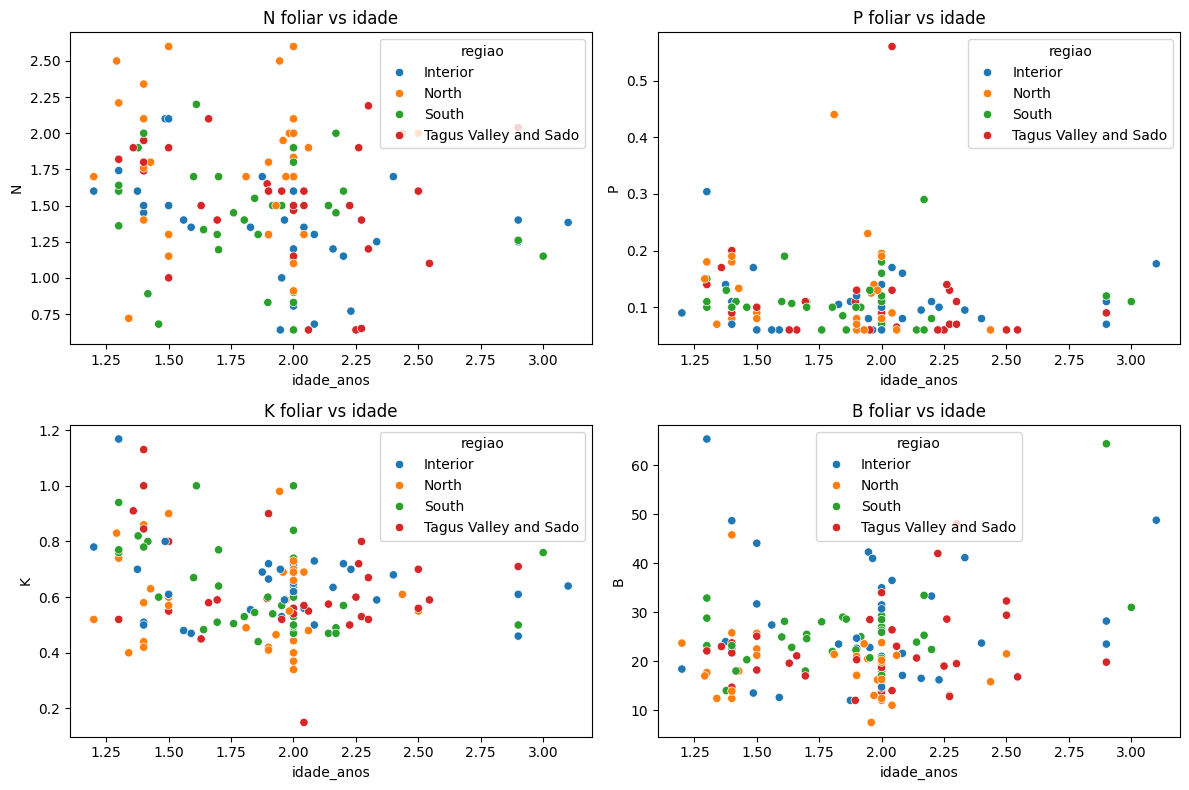

,N,P,K,B,idade_anos,acm
N,1.00,0.23,0.25,-0.03,-0.19,0.27
P,0.23,1.00,0.19,0.09,-0.10,-0.06
K,0.25,0.19,1.00,0.13,-0.23,-0.08
B,-0.03,0.09,0.13,1.00,0.13,-0.08
idade_anos,-0.19,-0.10,-0.23,0.13,1.00,-0.14
acm,0.27,-0.06,-0.08,-0.08,-0.14,1.00


In [10]:
# Integrar informação foliar com características do povoamento
dados_produtividade = folhas_visita.merge(
    observacoes[
        ["id", "ano", "idade_anos", "acm", "area_ha", "regiao", "regime"]
    ],
    on=["id", "ano"],
    how="inner"
)

# Estatísticas por região
print("MÉDIAS DOS NUTRIENTES POR REGIÃO")

display(
    dados_produtividade.groupby("regiao")[["N", "P", "K", "B"]]
    .mean()
    .round(3)
)

# Relação entre idade e nutrientes
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, nutriente in zip(axes.flat, ["N", "P", "K", "B"]):
    sns.scatterplot(
        data=dados_produtividade,
        x="idade_anos",
        y=nutriente,
        hue="regiao",
        ax=ax
    )
    ax.set_title(f"{nutriente} foliar vs idade")

plt.tight_layout()
plt.show()

# Correlações com produtividade e idade
display(
    dados_produtividade[
        ["N", "P", "K", "B", "idade_anos", "acm"]
    ].corr().round(2)
)

O que vamos interpretar:
- Se as concentrações dos nutrientes variam com a idade.
- Se existem diferenças entre regiões.
- Se a nutrição apresenta alguma associação com o crescimento médio anual (acm).
- Se a idade e a região devem ser consideradas variáveis explicativas.

É importante não confundir associação com efeito causal. A produtividade também depende de fatores como material genético, condições edafoclimáticas e gestão florestal.

A análise das médias regionais revela diferenças descritivas nas concentrações dos nutrientes foliares.

O Norte apresenta a maior concentração média de N (1,783), enquanto o Interior apresenta a menor (1,363). Para o boro, verifica-se o padrão inverso: o Interior apresenta a maior concentração média (27,769), enquanto o Norte apresenta a menor (19,138).

As concentrações médias de P e K apresentam diferenças mais reduzidas entre regiões.

Relativamente à idade, as correlações com as concentrações foliares são fracas, variando entre -0,23 e 0,13.

A relação entre N e ACM apresenta uma correlação positiva fraca (r = 0,27), enquanto os restantes nutrientes apresentam correlações próximas de zero com a produtividade.

Os resultados não demonstram relações lineares fortes entre a nutrição foliar, a idade e a produtividade, mas sugerem que estas variáveis podem contribuir para contextualizar as diferenças observadas entre povoamentos.

Implicação para a modelação: região, idade e regime devem ser mantidos como potenciais variáveis explicativas. A produtividade deve ser considerada sobretudo numa análise complementar, não como variável de entrada automática.

**Bloco 8 — Exploração dos dados climáticos ERA5-Land**

Já temos um ficheiro climático com informação para as 144 localizações/visitas.

O que precisamos de demonstrar é:
1. Que os dados climáticos foram carregados.
2. Que os identificadores e anos correspondem aos dados RAIZ.
3. Que as variáveis apresentam valores plausíveis.
4. Que conseguimos relacionar os indicadores climáticos com os nutrientes foliares.

Primeiro: caracterização dos dados climáticos.

ESTATÍSTICAS DOS INDICADORES CLIMÁTICOS


,count,mean,std,min,25%,50%,75%,max
temp_media_anual,141.0,16.02,1.21,12.81,15.16,16.30,16.98,18.01
temp_max_absoluta,141.0,36.53,2.69,29.40,34.39,36.62,38.58,41.98
temp_min_absoluta,141.0,0.26,2.05,-4.51,-1.24,0.18,1.54,6.87
precip_total_anual,144.0,2031.23,1031.16,0.00,1256.80,1736.30,2645.00,5012.80
evap_potencial_anual,144.0,4420.46,879.08,0.00,3968.72,4417.35,5031.30,6163.00
humidade_solo_l1,141.0,0.23,0.06,0.12,0.19,0.24,0.28,0.32
humidade_solo_l2,141.0,0.25,0.05,0.13,0.20,0.26,0.29,0.33
balanco_hidrico_anual,144.0,-2389.23,1467.56,-4855.10,-3524.65,-2523.45,-1497.25,1172.10
amplitude_termica_anual,141.0,36.27,3.34,25.33,34.49,36.85,38.73,41.79
gradiente_humidade_solo,141.0,0.02,0.01,-0.00,0.01,0.02,0.02,0.04


VALORES OMISSOS


,Valores omissos
temp_media_anual,3
temp_max_absoluta,3
temp_min_absoluta,3
precip_total_anual,0
evap_potencial_anual,0
humidade_solo_l1,3
humidade_solo_l2,3
balanco_hidrico_anual,0
amplitude_termica_anual,3
gradiente_humidade_solo,3


LIMITES DAS COORDENADAS


,lat_original,lon_original
count,144.000,144.000
mean,39.451,-8.180
std,1.232,0.496
min,37.275,-9.244
25%,38.526,-8.497
50%,39.658,-8.290
75%,40.187,-7.920
max,41.835,-6.969


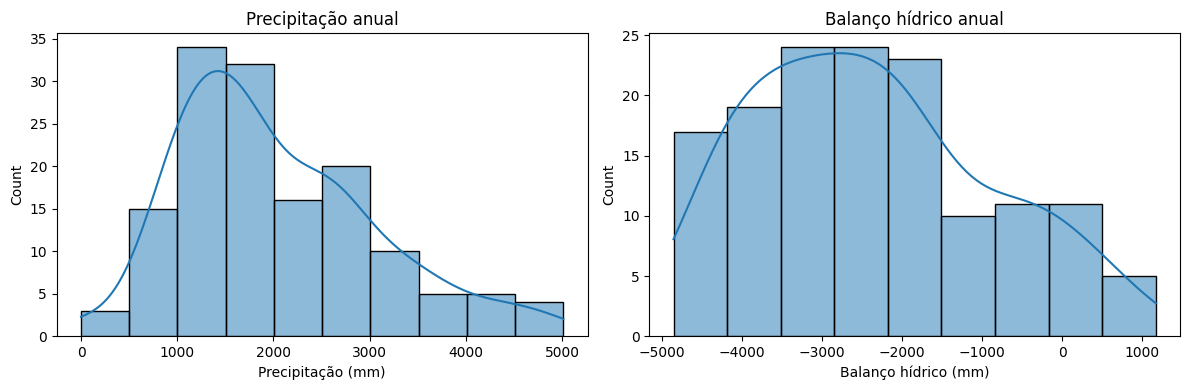

In [11]:
variaveis_clima = [
    "temp_media_anual",
    "temp_max_absoluta",
    "temp_min_absoluta",
    "precip_total_anual",
    "evap_potencial_anual",
    "humidade_solo_l1",
    "humidade_solo_l2",
    "balanco_hidrico_anual",
    "amplitude_termica_anual",
    "gradiente_humidade_solo"
]

# Estatísticas descritivas
print("ESTATÍSTICAS DOS INDICADORES CLIMÁTICOS")

display(
    clima[variaveis_clima]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .T.round(2)
)

# Valores omissos
print("VALORES OMISSOS")

display(
    clima[variaveis_clima].isna().sum()
    .to_frame("Valores omissos")
)

# Distribuição espacial das coordenadas
print("LIMITES DAS COORDENADAS")

display(
    clima[["lat_original", "lon_original"]].describe().round(3)
)

# Distribuição dos indicadores hídricos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    clima["precip_total_anual"].dropna(),
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Precipitação anual")
axes[0].set_xlabel("Precipitação (mm)")

sns.histplot(
    clima["balanco_hidrico_anual"].dropna(),
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Balanço hídrico anual")
axes[1].set_xlabel("Balanço hídrico (mm)")

plt.tight_layout()
plt.show()


Segundo: validar a correspondência entre os dados RAIZ e o clima.

O ficheiro climático utiliza localizacao_id, enquanto o Excel utiliza id. A análise inicial indica que os dois identificadores correspondem, e que os pares de ID e ano coincidem.

Vamos demonstrar isso explicitamente:

In [12]:
# Correspondência entre identificadores e anos
ids_raiz = set(zip(observacoes["id"], observacoes["ano"]))

ids_clima = set(zip(clima["localizacao_id"], clima["ano"]))

print("Pares ID/ano RAIZ:", len(ids_raiz))
print("Pares ID/ano clima:", len(ids_clima))
print("Pares coincidentes:", len(ids_raiz.intersection(ids_clima)))
print("Pares em falta no clima:", len(ids_raiz - ids_clima))
print("Pares adicionais no clima:", len(ids_clima - ids_raiz))

# Integração das fontes
clima_integrado = observacoes.merge(
    clima,
    left_on=["id", "ano"],
    right_on=["localizacao_id", "ano"],
    how="left",
    validate="one_to_one"
)

print("\nDimensão da tabela integrada:", clima_integrado.shape)

display(
    clima_integrado[
        ["id", "ano", "regiao", "temp_media_anual",
         "precip_total_anual", "balanco_hidrico_anual"]
    ].head(10)
)


Pares ID/ano RAIZ: 144
Pares ID/ano clima: 144
Pares coincidentes: 144
Pares em falta no clima: 0
Pares adicionais no clima: 0

Dimensão da tabela integrada: (144, 23)


,id,ano,regiao,temp_media_anual,precip_total_anual,balanco_hidrico_anual
0,1,2019,Interior,13.71,2452.8,-2083.9
1,2,2019,Interior,16.40,1269.1,-4017.8
2,3,2019,North,13.96,3281.7,-639.5
3,4,2019,North,15.26,2231.7,-2005.7
4,5,2019,North,14.44,2675.7,-964.8
5,6,2019,South,16.49,842.5,-4188.8
6,7,2019,South,16.53,858.1,-4087.6
7,8,2019,South,16.49,842.5,-4188.8
8,9,2019,Tagus Valley and Sado,15.88,1655.1,-3581.6
9,10,2019,Tagus Valley and Sado,16.53,1142.4,-4048.7


Terceiro: explorar a relação entre clima e nutrição.

Vamos agregar as amostras foliares por visita, tal como fizemos na análise anterior, e integrar os dados climáticos.

,temp_media_anual,precip_total_anual,evap_potencial_anual,balanco_hidrico_anual,humidade_solo_l1,humidade_solo_l2
N,-0.26,0.23,-0.20,0.29,0.22,0.24
P,-0.07,-0.03,0.06,-0.05,0.08,0.06
K,0.11,-0.24,0.14,-0.25,-0.21,-0.21
B,0.09,-0.20,0.11,-0.21,-0.10,-0.12


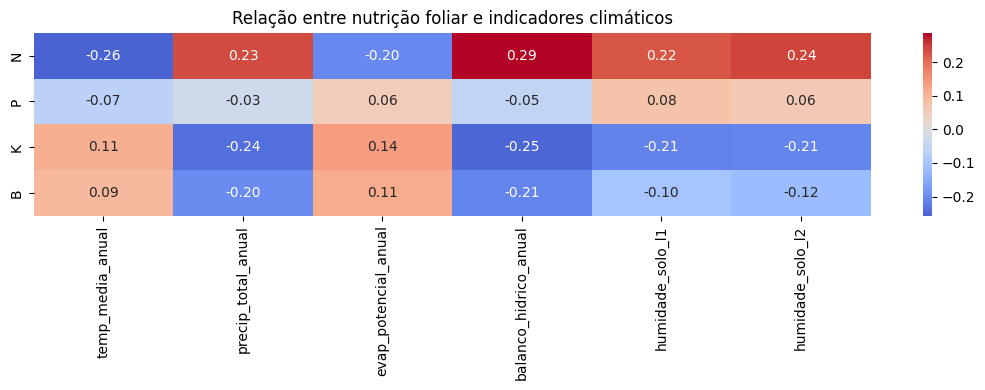

In [13]:
# Integrar nutrientes foliares e clima
folha_clima = folhas_visita.merge(
    clima,
    left_on=["id", "ano"],
    right_on=["localizacao_id", "ano"],
    how="left",
    validate="one_to_one"
)

# Variáveis climáticas selecionadas
clima_selecao = [
    "temp_media_anual",
    "precip_total_anual",
    "evap_potencial_anual",
    "balanco_hidrico_anual",
    "humidade_solo_l1",
    "humidade_solo_l2"
]

# Matriz de correlação
correlacoes_clima = folha_clima[
    ["N", "P", "K", "B"] + clima_selecao
].corr()

resultado_clima = correlacoes_clima.loc[
    ["N", "P", "K", "B"],
    clima_selecao
]

display(resultado_clima.round(2))

# Visualização
plt.figure(figsize=(11, 4))

sns.heatmap(
    resultado_clima,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Relação entre nutrição foliar e indicadores climáticos")
plt.tight_layout()
plt.show()


O que queremos investigar:
- Se temperaturas mais elevadas estão associadas a diferenças nas concentrações foliares.
- Se a precipitação apresenta alguma associação com os nutrientes.
- Se o balanço hídrico pode ajudar a caracterizar condições de défice de água.
- Se a humidade do solo estimada pelo ERA5-Land apresenta relações com a nutrição.

Há uma ressalva metodológica importante: os indicadores climáticos são anuais, não correspondem necessariamente ao período exato de recolha das folhas. Além disso, os dados ERA5-Land representam estimativas numa grelha espacial de aproximadamente 9 km, não medições diretas em cada parcela.

Também devemos verificar os três registos com valores nulos em algumas variáveis e os valores zero de precipitação e evaporação potencial. O balanço hídrico muito negativo em grande parte das observações merece validação das unidades e convenções de sinal antes de ser interpretado como défice hídrico real.

A integração dos dados ERA5-Land com os registos RAIZ foi realizada com sucesso, tendo sido possível estabelecer correspondência entre os 144 pares de identificadores e anos.

Os indicadores climáticos incluem informação sobre temperatura, precipitação, evaporação potencial e humidade do solo, permitindo enriquecer a base de dados com informação ambiental.

A análise exploratória inicial revelou algumas associações fracas entre os indicadores climáticos e as concentrações foliares, nomeadamente para N e K.

Contudo, foram identificados valores de precipitação e evaporação potencial que exigem validação das unidades e do procedimento de acumulação temporal.

Assim, os dados climáticos encontram-se tecnicamente integrados, mas a validação física dos indicadores hídricos deverá ser concluída antes da sua utilização na modelação.

**Bloco 9 — Consultas SQL**

Criar uma base de dados SQLite e demonstrar consultas

Fazer consultas às fontes de dados e apresentar tabelas de resultados.

Criar uma pequena base de dados SQLite diretamente no Colab.

In [14]:
# Criar base de dados SQLite
con = sqlite3.connect("eucanutri_workshop.sqlite")

# Exportar tabelas para SQLite
tabelas_sql = {
    "folhas": folhas,
    "solo": solo,
    "diagnose_visual": diagnose,
    "observacoes": observacoes,
    "referencias": referencias,
    "clima": clima
}

for nome, df in tabelas_sql.items():
    df.to_sql(nome, con, if_exists="replace", index=False)

print("Base de dados criada com sucesso.")

# Consulta 1: número de visitas por ano
q1 = """
SELECT ano, COUNT(DISTINCT id) AS numero_visitas
FROM observacoes
GROUP BY ano
ORDER BY ano;
"""

display(pd.read_sql_query(q1, con))

# Consulta 2: estatísticas dos nutrientes foliares
q2 = """
SELECT
    COUNT(*) AS n_amostras,
    ROUND(AVG(N), 3) AS media_N,
    ROUND(MIN(N), 3) AS minimo_N,
    ROUND(MAX(N), 3) AS maximo_N,
    ROUND(AVG(P), 3) AS media_P,
    ROUND(AVG(K), 3) AS media_K,
    ROUND(AVG(B), 3) AS media_B
FROM folhas;
"""

display(pd.read_sql_query(q2, con))

# Consulta 3: distribuição das classes de azoto
q3 = """
SELECT classe_N, COUNT(*) AS numero_amostras
FROM folhas
GROUP BY classe_N
ORDER BY numero_amostras DESC;
"""

display(pd.read_sql_query(q3, con))

# Consulta 4: integração entre observações e clima
q4 = """
SELECT
    COUNT(*) AS numero_visitas,
    ROUND(AVG(c.temp_media_anual), 2) AS temperatura_media,
    ROUND(AVG(c.precip_total_anual), 2) AS precipitacao_media,
    ROUND(AVG(c.balanco_hidrico_anual), 2) AS balanco_hidrico_medio
FROM observacoes o
LEFT JOIN clima c
    ON o.id = c.localizacao_id
    AND o.ano = c.ano;
"""

display(pd.read_sql_query(q4, con))

con.close()


Base de dados criada com sucesso.


,ano,numero_visitas
0,2019,20
1,2020,21
2,2021,20
3,2022,20
4,2023,22
5,2024,20
6,2025,21


,n_amostras,media_N,minimo_N,maximo_N,media_P,media_K,media_B
0,190,1.52,0.64,2.6,0.114,0.628,24.537


,classe_N,numero_amostras
0,Média,67
1,Baixa,58
2,Muito baixa,38
3,Alta,27


,numero_visitas,temperatura_media,precipitacao_media,balanco_hidrico_medio
0,144,16.02,2031.23,-2389.23


Isto permite demonstrar que:
- Os dados estão estruturados em tabelas.
- As tabelas podem ser consultadas através de SQL.
- É possível calcular estatísticas diretamente na base de dados.
- É possível cruzar informação de diferentes fontes.

Foi criada uma base de dados SQLite contendo as tabelas de folhas, solo, diagnóstico visual, observações, referências e clima.

Foram executadas consultas SQL para obter:
- Distribuição das visitas por ano.
- Estatísticas descritivas dos nutrientes foliares.
- Distribuição das classes nutricionais.
- Estatísticas agregadas dos indicadores climáticos após integração com as observações.

Os resultados obtidos através de SQL são consistentes com os resultados da análise exploratória realizada em Python.

Esta etapa demonstra que os dados se encontram estruturados e podem ser consultados para produzir informação estatística e cruzar diferentes fontes.

**Que variáveis devemos propor para a fase de modelação?**

Este é provavelmente o resultado mais importante da tua análise enquanto Data Scientist: demonstrar que sabes transformar os dados disponíveis em variáveis relevantes para o problema.

A minha proposta inicial é:

| Grupo | Variáveis | Justificação |
| :--- | :--- | :--- |
| **Nutrição foliar** | N, P, K, B | Identificação do estado nutricional |
| **Classes nutricionais** | classe_N, classe_P, classe_K, classe_B | Identificação de potenciais deficiências |
| **Solo** | pH, matéria orgânica, P, K, B, Ca, Mg | Caracterização da disponibilidade e condições do solo |
| **Clima** | Temperatura, precipitação, evaporação potencial | Caracterização das condições ambientais |
| **Água** | Balanço hídrico, humidade do solo | Exploração de condições de disponibilidade hídrica |
| **Povoamento** | Idade, região, regime, rotação | Contextualização do estado nutricional |
| **Produtividade** | ACM, área | Exploração da relação entre nutrição e crescimento |
| **Diagnóstico visual** | Vitalidade, abrangência, desordens | Informação complementar para diagnóstico |

Não devemos utilizar todas estas variáveis indiscriminadamente.

Por exemplo:
- As concentrações foliares podem ajudar a definir o estado nutricional de referência.
- O solo e o clima podem funcionar como variáveis explicativas.
- A idade e o material genético podem ajudar a contextualizar as diferenças.
- O diagnóstico visual pode constituir uma fonte de informação complementar ou uma variável-alvo, dependendo da definição do problema.
- A produtividade pode ser utilizada para estudar consequências do estado nutricional, mas não deve ser automaticamente considerada uma variável de entrada.

Se o objetivo for prever uma deficiência a partir de imagens e informação contextual, devemos evitar utilizar como preditores variáveis que revelem diretamente a classificação que queremos prever. Isso poderia provocar data leakage.

Também será necessário definir se o modelo pretende prever uma deficiência por nutriente, um estado nutricional global ou uma categoria de diagnóstico visual.

**Conclusões preliminares que já podes levar para o workshop**

Com base na inspeção dos ficheiros, já temos vários findings que podem ser apresentados.

| Nº | Finding | Implicação |
| :--- | :--- | :--- |
| 1 | Existem 144 visitas entre 2019 e 2025. | Base histórica disponível para análise. |
| 2 | Existem 190 amostras foliares. | Permite explorar variação entre materiais genéticos e amostras. |
| 3 | Existem 144 registos de solo. | Permite estudar relações entre solo e nutrição. |
| 4 | Existem 154 fichas de diagnóstico visual. | Permite explorar sintomas observados no campo. |
| 5 | O ID 32 não tem registo nas tabelas foliar e de solo. | Necessário considerar a cobertura dos dados na integração. |
| 6 | Existem valores omissos em várias variáveis do solo e das folhas. | A seleção de variáveis deve considerar a completude. |
| 7 | N apresenta 96 amostras nas classes baixa e muito baixa. | Justifica aprofundar a análise de azoto. |
| 8 | P apresenta 90 amostras na classe baixa. | Justifica aprofundar a análise de fósforo. |
| 9 | K e B apresentam maior concentração de amostras na classe média. | Permite caracterizar o estado nutricional e procurar casos extremos. |
| 10 | Existem 53 fichas com sintomas nutricionais identificados. | Possibilidade de explorar a relação entre observações e análises laboratoriais. |
| 11 | Existem registos de desordens não nutricionais. | É necessário distinguir deficiências de outros fatores de stress. |
| 12 | O CSV climático contém 144 registos e permite correspondência por ID e ano. | Possibilidade de enriquecer os dados RAIZ com fatores ambientais. |

Estes são findings preliminares, não conclusões científicas definitivas. Precisamos de executar os restantes blocos para confirmar as relações entre as variáveis.

---

A. Confirmar exatamente quais os IDs sem amostras foliares e de solo

In [15]:
ids_observacoes = set(observacoes["id"])
ids_folhas = set(folhas["id"])
ids_solo = set(solo["id"])

print("IDs sem amostras foliares:",
      sorted(ids_observacoes - ids_folhas))

print("IDs sem análises de solo:",
      sorted(ids_observacoes - ids_solo))

print("IDs sem diagnóstico visual:",
      sorted(ids_observacoes - set(diagnose["id"])))

IDs sem amostras foliares: [32]
IDs sem análises de solo: [32]
IDs sem diagnóstico visual: []


Isto permite identificar concretamente as visitas sem cada tipo de informação.

B. Confirmar a dimensão das amostras utilizadas nas correlações

In [16]:
# Número de observações válidas em cada correlação
variaveis_correlacao = [
    "N", "P", "K", "B",
    "solo_ph_h2o", "solo_mo_pct",
    "solo_P", "solo_K", "solo_Ca",
    "solo_Mg", "solo_B", "solo_gsb_pct"
]

display(
    folha_solo[variaveis_correlacao]
    .corr()
    .round(2)
)

display(
    folha_solo[variaveis_correlacao]
    .notna()
    .astype(int)
    .T.dot(
        folha_solo[variaveis_correlacao]
        .notna()
        .astype(int)
    )
)


,N,P,K,B,solo_ph_h2o,solo_mo_pct,solo_P,solo_K,solo_Ca,solo_Mg,solo_B,solo_gsb_pct
N,1.00,0.23,0.25,-0.03,-0.23,0.27,0.02,-0.06,-0.03,-0.10,0.22,-0.15
P,0.23,1.00,0.19,0.09,0.13,-0.05,0.04,0.02,0.09,0.20,0.21,0.06
K,0.25,0.19,1.00,0.13,0.08,-0.16,-0.02,0.16,0.09,-0.01,0.02,0.16
B,-0.03,0.09,0.13,1.00,0.22,-0.14,-0.24,0.21,0.01,0.01,0.09,0.12
solo_ph_h2o,-0.23,0.13,0.08,0.22,1.00,-0.55,-0.35,0.19,0.38,0.27,-0.05,0.63
solo_mo_pct,0.27,-0.05,-0.16,-0.14,-0.55,1.00,0.13,-0.05,-0.09,-0.26,0.55,-0.52
solo_P,0.02,0.04,-0.02,-0.24,-0.35,0.13,1.00,0.14,0.19,0.11,0.04,0.13
solo_K,-0.06,0.02,0.16,0.21,0.19,-0.05,0.14,1.00,0.41,0.42,0.38,0.37
solo_Ca,-0.03,0.09,0.09,0.01,0.38,-0.09,0.19,0.41,1.00,0.58,0.18,0.66
solo_Mg,-0.10,0.20,-0.01,0.01,0.27,-0.26,0.11,0.42,0.58,1.00,-0.08,0.55


,N,P,K,B,solo_ph_h2o,solo_mo_pct,solo_P,solo_K,solo_Ca,solo_Mg,solo_B,solo_gsb_pct
N,143,143,143,143,143,143,108,141,141,130,63,123
P,143,143,143,143,143,143,108,141,141,130,63,123
K,143,143,143,143,143,143,108,141,141,130,63,123
B,143,143,143,143,143,143,108,141,141,130,63,123
solo_ph_h2o,143,143,143,143,143,143,108,141,141,130,63,123
solo_mo_pct,143,143,143,143,143,143,108,141,141,130,63,123
solo_P,108,108,108,108,108,108,108,106,107,99,53,88
solo_K,141,141,141,141,141,141,106,141,139,130,63,122
solo_Ca,141,141,141,141,141,141,107,139,141,130,62,122
solo_Mg,130,130,130,130,130,130,99,130,130,130,60,114


A segunda tabela mostra quantos pares completos existem para cada correlação. É importante porque algumas relações podem ter sido calculadas com menos observações devido aos valores omissos.

---

1. Preparar uma tabela estatística completa

In [17]:
# Estatísticas descritivas das concentrações foliares

nutrientes = ["N", "P", "K", "B"]

resumo_nutrientes = folhas[nutrientes].describe().T

resumo_nutrientes = resumo_nutrientes[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

resumo_nutrientes.columns = [
    "N",
    "Média",
    "Desvio padrão",
    "Mínimo",
    "Q1",
    "Mediana",
    "Q3",
    "Máximo"
]

display(resumo_nutrientes.round(3))

,N,Média,Desvio padrão,Mínimo,Q1,Mediana,Q3,Máximo
N,190.0,1.520,0.426,0.64,1.30,1.53,1.800,2.60
P,190.0,0.114,0.071,0.06,0.07,0.10,0.130,0.56
K,190.0,0.628,0.172,0.15,0.51,0.60,0.700,1.24
B,190.0,24.537,13.468,4.00,18.00,21.85,28.175,122.40


2. Preparar estatísticas do solo

In [18]:
# Estatísticas descritivas das principais variáveis do solo

variaveis_solo = [
    "solo_ph_h2o",
    "solo_mo_pct",
    "P",
    "K",
    "Ca",
    "Mg",
    "B"
]

variaveis_existentes = [
    v for v in variaveis_solo if v in solo.columns
]

resumo_solo = solo[variaveis_existentes].describe().T

display(
    resumo_solo[
        ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(3)
)

,count,mean,std,min,25%,50%,75%,max
P,109.0,6.464,4.776,0.44,2.600,6.000,8.000,29.00
K,142.0,0.160,0.074,0.03,0.110,0.150,0.200,0.38
Ca,142.0,0.892,1.109,0.03,0.252,0.565,1.162,10.00
Mg,131.0,0.603,0.652,0.08,0.195,0.350,0.730,4.21
B,64.0,0.562,0.241,0.10,0.400,0.500,0.700,1.00


3. Preparar uma tabela de valores omissos

In [19]:
tabelas = {
    "Folhas": folhas,
    "Solo": solo,
    "Diagnóstico visual": diagnose,
    "Observações": observacoes,
    "Clima": clima
}

for nome, df in tabelas.items():

    print("\n", nome.upper())

    resumo = pd.DataFrame({
        "Valores omissos": df.isna().sum(),
        "Percentagem (%)": (df.isna().mean() * 100).round(1)
    })

    display(
        resumo[resumo["Valores omissos"] > 0]
        .sort_values("Percentagem (%)", ascending=False)
    )


 FOLHAS


,Valores omissos,Percentagem (%)
C,166,87.4
parcela,162,85.3
zona_homogenea,119,62.6
S,64,33.7



 SOLO


,Valores omissos,Percentagem (%)
zona_homogenea,124,86.1
textura,124,86.1
terra_fina_pct,123,85.4
N,102,70.8
ce_dsm,102,70.8
B,80,55.6
classe_B,80,55.6
Cu,40,27.8
Mn,40,27.8
Fe,40,27.8



 DIAGNÓSTICO VISUAL


,Valores omissos,Percentagem (%)
material_genetico,126,81.8
obs,43,27.9
tipo_desordem,29,18.8
abrangencia,23,14.9
desordem_nutricional,7,4.5
desordem_nao_nutricional,6,3.9
vitalidade_normal,1,0.6



 OBSERVAÇÕES


,Valores omissos,Percentagem (%)
ciclo,20,13.9



 CLIMA


,Valores omissos,Percentagem (%)
temp_media_anual,3,2.1
temp_max_absoluta,3,2.1
temp_min_absoluta,3,2.1
humidade_solo_l1,3,2.1
humidade_solo_l2,3,2.1
amplitude_termica_anual,3,2.1
gradiente_humidade_solo,3,2.1
